本 notebook 是 [M03.4 数据划分、泄漏与分布偏移](../notes/04-splitting-leakage-shift.qmd) 的实例讲解。

1. 1. 相邻结构与轨迹分组
2. 2. 时间顺序、窗口与 gap
3. 3. 结构相似性分组与距离审计
4. 4. 偏移诊断与重要性加权

在 VS Code 中选择仓库 `.venv` 内核，逐单元运行；运行结果随文件保存。示例使用固定随机种子和合成数据。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib_inline.backend_inline import set_matplotlib_formats
from scipy.stats import norm
from sklearn.cluster import AgglomerativeClustering
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mean_squared_error, pairwise_distances
from sklearn.model_selection import (
    GroupShuffleSplit,
    TimeSeriesSplit,
    cross_val_score,
    train_test_split,
)
from sklearn.neighbors import KNeighborsRegressor, NearestNeighbors

from semiai.plotting import BLUE, ORANGE, use_style

use_style()
set_matplotlib_formats("svg")
rng = np.random.default_rng(42)

## 1. 相邻结构与轨迹分组

将轨迹身份编码在接近的描述符中，标签具有轨迹专属偏移；用相同的 1-NN 比较两个预测问题。

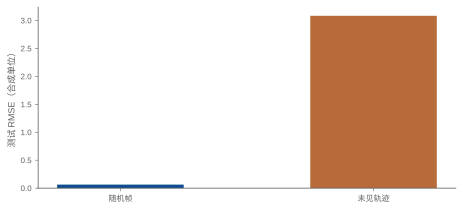

随机帧 RMSE: 0.06348785627474628 共享轨迹数: 24
未见轨迹 RMSE: 3.083314136376574 共享轨迹数: 0


In [2]:
local = np.random.default_rng(12)
groups = np.repeat(np.arange(24), 30)
centers = local.normal(0, 3, (24, 4))
X = centers[groups] + local.normal(0, 0.04, (len(groups), 4))
y = local.normal(0, 2, 24)[groups] + local.normal(0, 0.04, len(groups))
idx = np.arange(len(y))
splits = {
    "随机帧": train_test_split(idx, test_size=0.25, random_state=42),
    "未见轨迹": next(
        GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42).split(X, y, groups)
    ),
}
errors = []
for _name, (train, test) in splits.items():
    model = KNeighborsRegressor(n_neighbors=1).fit(X[train], y[train])
    errors.append(np.sqrt(mean_squared_error(y[test], model.predict(X[test]))))
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.bar(list(splits), errors, color=[BLUE, ORANGE], width=0.5)
ax.set(ylabel="测试 RMSE（合成单位）")
fig.tight_layout()
plt.show()

for (name, (train, test)), error in zip(splits.items(), errors, strict=True):
    overlap = set(groups[train]) & set(groups[test])
    print(name, "RMSE:", error, "共享轨迹数:", len(overlap))
assert not (set(groups[splits["未见轨迹"][0]]) & set(groups[splits["未见轨迹"][1]]))

读法：随机帧评估的是已见轨迹内插，分组评估的是未见轨迹迁移；这里标签刻意包含不可泛化的组偏移，因此差距来自已知机制，不能当作真实 MD 的定量结论。

## 2. 时间顺序、窗口与 gap

记录每个时间折中最后训练时刻、最早测试时刻，检查窗口长度与间隔的关系。

In [3]:
n = 140
window = 8
series = np.cumsum(rng.normal(size=n))
features = np.array([series[t - window : t] for t in range(window, n)])
target = series[window:]
times = np.arange(window, n)
for fold, (train, test) in enumerate(
    TimeSeriesSplit(n_splits=3, gap=window, test_size=20).split(features)
):
    print(
        "fold",
        fold,
        "train end",
        times[train[-1]],
        "test start",
        times[test[0]],
        "最早测试输入",
        times[test[0]] - window,
    )
    assert times[test[0]] - window > times[train[-1]]
# 在时刻 t 预测 t+1；先 shift 再 rolling 避免把目标本身放进特征。
table = pd.DataFrame({"signal": series})
table["past_mean"] = table.signal.shift(1).rolling(window).mean()
print(table.iloc[window : window + 3])

fold 0 train end 71 test start 80 最早测试输入 72
fold 1 train end 91 test start 100 最早测试输入 92
fold 2 train end 111 test start 120 最早测试输入 112
      signal  past_mean
8  -2.502669  -0.925983
9  -3.355713  -1.276906
10 -2.476315  -1.604462


读法：gap 按样本索引计量，不自动等于物理时间；该例选择保守的窗口隔离，真实预测也可以合法使用预测时已知的历史，关键是定义当时的信息集合。

## 3. 结构相似性分组与距离审计

未知轨迹标签时，以预先规定的描述符距离构造相似簇，避免近重复跨集合；同时检查阈值诱导的组大小。

In [4]:
similar_groups = AgglomerativeClustering(
    n_clusters=None, distance_threshold=0.6, linkage="single"
).fit_predict(X)
train, test = next(
    GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=4).split(X, groups=similar_groups)
)
neighbors = NearestNeighbors(n_neighbors=1).fit(X[train])
distance = neighbors.kneighbors(X[test])[0].ravel()
print(
    "组数:",
    len(np.unique(similar_groups)),
    "组大小分位数:",
    np.quantile(np.bincount(similar_groups), [0, 0.5, 1]),
)
print("测试到训练最近距离分位数:", np.quantile(distance, [0, 0.5, 1]))
assert pairwise_distances(X[test], X[train]).min() >= 0.6 - 1e-12

组数: 24 组大小分位数: [30. 30. 30.]
测试到训练最近距离分位数: [2.14183268 3.04065063 5.50864081]


读法：单链接把阈值内邻接边连接成组，因而训练测试间没有小于阈值的边；链式连接可能产生巨组。距离依赖表示和尺度，不能替代成分、相态等领域约束。

## 4. 偏移诊断与重要性加权

构造只改变 p(x) 的情形，比较来源域、目标域和加权来源域风险；再展示相同 p(x) 下的概念偏移不能由无标签特征发现。

In [5]:
source = rng.normal(size=20000)
destination = rng.normal(1.0, 1.0, 20000)
# 固定预测器为零，真实条件均值 x²；损失为 x⁴。
weights = np.exp(source - 0.5)
print(
    "source risk",
    np.mean(source**4),
    "target risk",
    np.mean(destination**4),
    "weighted risk",
    np.mean(weights * source**4),
)
domain_x = np.r_[source[:1000], destination[:1000]][:, None]
domain_y = np.r_[np.zeros(1000), np.ones(1000)]
print(
    "域分类 AUC:",
    cross_val_score(LogisticRegression(), domain_x, domain_y, cv=5, scoring="roc_auc").mean(),
)
print("权重 ESS:", weights.sum() ** 2 / np.sum(weights**2))
x = rng.normal(size=5000)
print("相同特征，不同条件机制的风险:", np.mean((x - x) ** 2), np.mean((-x - x) ** 2))
assert np.allclose(weights, norm.pdf(source, loc=1) / norm.pdf(source))

source risk 3.0762465627282713 target risk 10.144421012032875 weighted risk 10.2449171839121
域分类 AUC: 0.76237
权重 ESS: 7370.056036186684
相同特征，不同条件机制的风险: 0.0 3.9373087967523315


读法：加权成立需要条件分布不变且目标支持被来源覆盖；有限样本权重尾部会增加方差。域可分说明特征分布不同，不能确定偏移类型，也不能检测所有概念变化。

## 小结

先定义未来对象和可用信息，再定义集合边界。泄漏破坏这个边界，分布偏移改变边界外的问题。保存组与时间信息、折内拟合预处理、检查近重复和支持覆盖，才能把评估分数解释为一个明确任务上的证据。